<a href="https://www.quantrocket.com"><img alt="QuantRocket logo" src="https://www.quantrocket.com/assets/img/notebook-header-logo.png"></a>

© Copyright Quantopian Inc.<br>
© Modifications Copyright QuantRocket LLC<br>
Licensed under the [Creative Commons Attribution 4.0](https://creativecommons.org/licenses/by/4.0/legalcode).<br>
<a href="https://www.quantrocket.com/disclaimer/">Disclaimer</a>

***
[Quant Finance Lectures (adapted Quantopian Lectures)](Introduction.ipynb) › Lecture 14 - Regression Model Instability
***

# Regression Model Instability

By Evgenia "Jenny" Nitishinskaya and Delaney Granizo-Mackenzie. Algorithms by David Edwards.

<a href="https://youtu.be/HMQ34PfhzGE" target="_blank">Quantopian video for this lecture ↗</a>


Regression analysis allows us to estimate coefficients in a function which approximately relates multiple data sets. We hypothesize a specific form for this function and then find coefficients which fit the data well, working under the assumption that deviations from the model can be considered noise.

When building such a model, we accept that it cannot perfectly predict the dependent variable. Here we would like to evaluate the accuracy of the model not by how well it explains the dependent variable, but by how <i>stable</i> it is (that is, how stable the regression coefficients are) with respect to our sample data. After all, if a model is truly a good fit, it should be similar, say, for two random halves of our data set that we model individually. Otherwise, we cannot assume that the model isn't simply an artifact of the particular sample of data we happened to choose, or that it will be predictive of new data points.

We'll be using linear regressions here for illustration purposes, but the same considerations apply for all regression models. Below we define a wrapper function for the linear regression from `statsmodels` so we can use it later.

In [1]:
import numpy as np
import pandas as pd
from statsmodels import regression, stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import scipy as sp

def linreg(X,Y):
    # Running the linear regression
    x = sm.add_constant(X) # Add a row of 1's so that our model has a constant term
    model = regression.linear_model.OLS(Y, x).fit()
    return model.params[0], model.params[1] # Return the coefficients of the linear model

## Biased noise

The particular sample we choose for the data affects the model generated, and unevenly distributed noise can lead to an inaccurate model. Below we're drawing from a normal distribution, but because we do not have very many data points, we get a significant downward bias. If we took more measurements, both of the regression coefficients would move toward zero.

Slope: 0.009072503822685537 Intercept: -0.4020774408530384


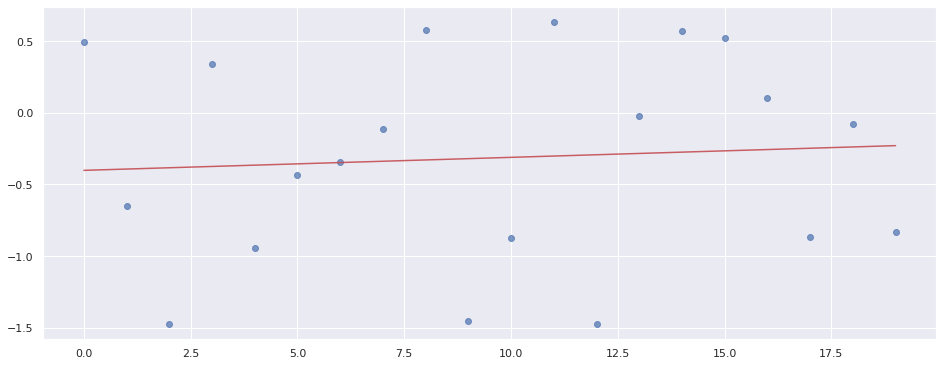

In [2]:
# Draw observations from normal distribution
np.random.seed(107) # Fix seed for random number generation
rand = np.random.randn(20)

# Conduct linear regression on the ordered list of observations
xs = np.arange(20)
a, b = linreg(xs, rand)
print('Slope:', b, 'Intercept:', a)

# Plot the raw data and the regression line
plt.scatter(xs, rand, alpha=0.7)
Y_hat = xs * b + a
plt.plot(xs, Y_hat, 'r', alpha=0.9);

<Axes: >

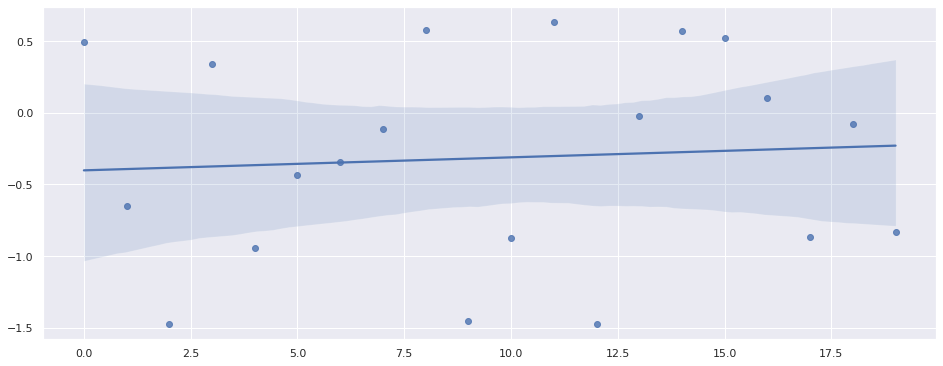

In [3]:
import seaborn

seaborn.regplot(x=xs, y=rand)

Slope: -0.0005693423631053359 Intercept: 0.009011767319021827


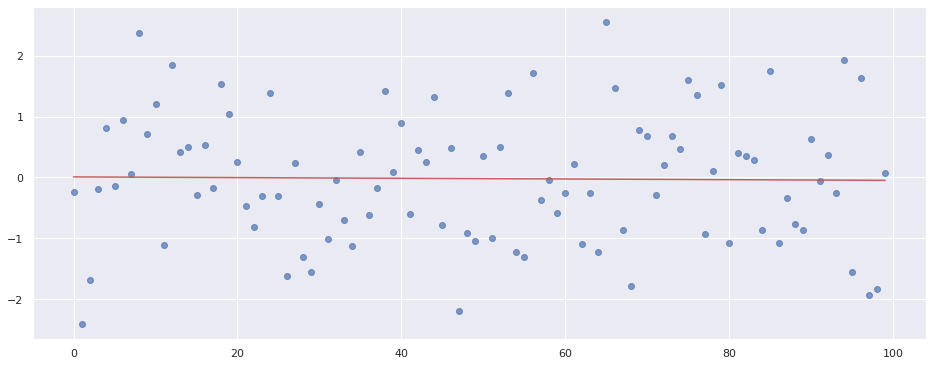

In [4]:
# Draw more observations
rand2 = np.random.randn(100)

# Conduct linear regression on the ordered list of observations
xs2 = np.arange(100)
a2, b2 = linreg(xs2, rand2)
print('Slope:', b2, 'Intercept:', a2)

# Plot the raw data and the regression line
plt.scatter(xs2, rand2, alpha=0.7)
Y_hat2 = xs2 * b2 + a2
plt.plot(xs2, Y_hat2, 'r', alpha=0.9);

Regression analysis is very sensitive to outliers. Sometimes these outliers contain information, in which case we want to take them into account; however, in cases like the above, they can simply be random noise. Although we often have many more data points than in the example above, we could have (for example) fluctuations on the order of weeks or months, which then significantly change the regression coefficients.

## Regime changes

A regime change (or structural break) is when something changes in the process generating the data, causing future samples to follow a different distribution. Below, we can see that there is a regime change for Exxon Mobil in late 2014, and splitting the data there results in a much better fit (in red) than a regression on the whole data set (yellow). In this case our regression model will not be predictive of future data points since the underlying system is no longer the same as in the sample. In fact, the regression analysis assumes that the errors are uncorrelated and have constant variance, which is often not be the case if there is a regime change.

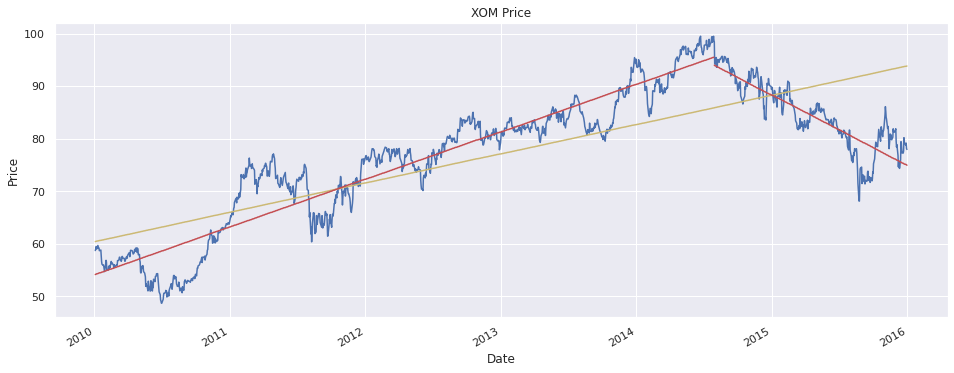

In [5]:
from quantrocket.master import get_securities
from quantrocket import get_prices

exxon_sid = get_securities(symbols="XOM", vendors='usstock').index[0]

start = '2010-01-01'
end = '2016-01-01'
prices = get_prices('usstock-free-1min', data_frequency='daily', sids=exxon_sid, fields='Close', start_date=start, end_date=end)
prices = prices.loc['Close'][exxon_sid]

# Manually set the point where we think a structural break occurs
breakpoint = 1150
xs = np.arange(len(prices))
xs2 = np.arange(breakpoint)
xs3 = np.arange(len(prices) - breakpoint)

# Perform linear regressions on the full data set, the data up to the breakpoint, and the data after
a, b = linreg(xs, prices.values)
a2, b2 = linreg(xs2, prices[:breakpoint].values)
a3, b3 = linreg(xs3, prices[breakpoint:].values)

Y_hat = pd.Series(xs * b + a, index=prices.index)
Y_hat2 = pd.Series(xs2 * b2 + a2, index=prices.index[:breakpoint])
Y_hat3 = pd.Series(xs3 * b3 + a3, index=prices.index[breakpoint:])

# Plot the raw data
prices.plot()
Y_hat.plot(color='y')
Y_hat2.plot(color='r')
Y_hat3.plot(color='r')
plt.title('XOM Price')
plt.ylabel('Price');

Of course, the more pieces we break our data set into, the more precisely we can fit to it. It's important to avoid fitting to noise, which will always fluctuate and is not predictive. We can test for the existence of a structural break, either at a particular point we have identified or in general. Below we use a test from `statsmodels` which computes the probability of observing the data if there were no breakpoint.

In [6]:
stats.diagnostic.breaks_cusumolsresid(
    regression.linear_model.OLS(prices, sm.add_constant(xs)).fit().resid)[1]

np.float64(2.058243263024887e-61)

## Multicollinearity

Above we were only considering regressions of one dependent variable against one independent one. However, we can also have multiple independent variables. This leads to instability if the independent variables are highly correlated.

Imagine we are using two independent variables, $X_1$ and $X_2$, which are very highly correlated. Then the coefficients may shift drastically if we add a new observation that is slightly better explained by one of the two than by the other. In the extreme case, if $X_1 = X_2$, then the choice of coefficients will depend on the particular linear regression algorithm.

Below, we run a multiple linear regression in which the independent variables are highly correlated. If we take our sample period to be 2013-01-01 to 2015-01-01, then the coefficients are approximately .10 and 1.03. But if we extend the period to 2015-04-01, the coefficients become approximately .55 and .07, respectively.

Constant: 31.67091871476559 MLR beta to AAPL: 0.09478435173254138 MLR beta to MSFT 1.0723677769884081


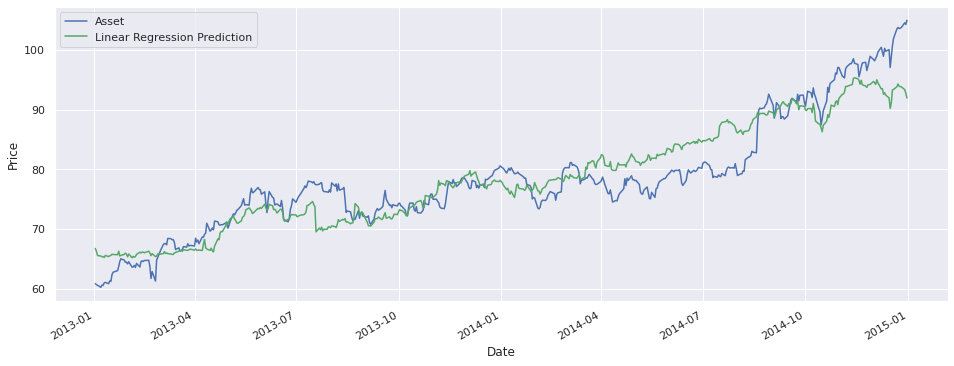

In [7]:
# Get pricing data for two tech stocks and HD
securities = get_securities(symbols=["MSFT", "AAPL", "HD"], vendors='usstock')

start = '2013-01-01'
end = '2015-01-01'

prices = get_prices('usstock-free-1min', data_frequency='daily', sids=securities.index.tolist(), fields='Close', start_date=start, end_date=end).loc["Close"]

sids_to_symbols = securities.Symbol.to_dict()
prices = prices.rename(columns=sids_to_symbols)

b1 = prices['AAPL']
b2 = prices['MSFT']
asset = prices['HD']

mlr = regression.linear_model.OLS(asset, sm.add_constant(np.column_stack((b1, b2)))).fit()
prediction = mlr.params.iloc[0] + mlr.params.iloc[1]*b1 + mlr.params.iloc[2]*b2
print('Constant:', mlr.params.iloc[0], 'MLR beta to AAPL:', mlr.params.iloc[1], 'MLR beta to MSFT', mlr.params.iloc[2])

# Plot the asset pricing data and the regression model prediction, just for fun
asset.plot()
prediction.plot();
plt.ylabel('Price')
plt.legend(['Asset', 'Linear Regression Prediction']);

Constant: 31.120007326986027 MLR beta to AAPL: 0.5656041915848801 MLR beta to MSFT 0.09379442671394982


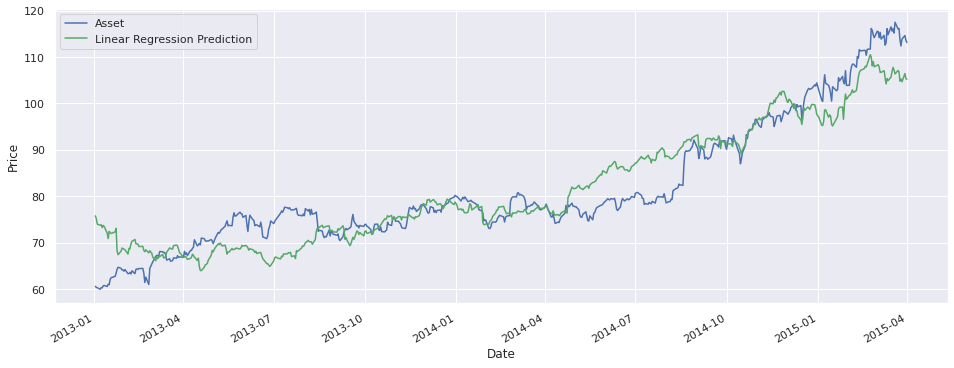

In [8]:
# Get pricing data for two tech stocks and HD
securities = get_securities(symbols=["MSFT", "AAPL", "HD"], vendors='usstock')

start = '2013-01-01'
end = '2015-04-01'

prices = get_prices('usstock-free-1min', data_frequency='daily', sids=securities.index.tolist(), fields='Close', start_date=start, end_date=end).loc["Close"]

sids_to_symbols = securities.Symbol.to_dict()
prices = prices.rename(columns=sids_to_symbols)

b1 = prices['AAPL']
b2 = prices['MSFT']
asset = prices['HD']

mlr = regression.linear_model.OLS(asset, sm.add_constant(np.column_stack((b1, b2)))).fit()
prediction = mlr.params.iloc[0] + mlr.params.iloc[1]*b1 + mlr.params.iloc[2]*b2
print('Constant:', mlr.params.iloc[0], 'MLR beta to AAPL:', mlr.params.iloc[1], 'MLR beta to MSFT', mlr.params.iloc[2])

# Plot the asset pricing data and the regression model prediction, just for fun
asset.plot()
prediction.plot();
plt.ylabel('Price')
plt.legend(['Asset', 'Linear Regression Prediction']);

We can check that our independent variables are correlated by computing their correlation coefficient. This number always lies between -1 and 1, and a value of 1 means that the two variables are perfectly correlated.

In [9]:
# Compute Pearson correlation coefficient
sp.stats.pearsonr(b1,b2)[0] # Second return value is p-value

np.float64(0.8597066549901703)

---

**Next Lecture:** [Multiple Linear Regression](Lecture15-Multiple-Linear-Regression.ipynb) 

[Back to Introduction](Introduction.ipynb) 

---

*This presentation is for informational purposes only and does not constitute an offer to sell, a solicitation to buy, or a recommendation for any security; nor does it constitute an offer to provide investment advisory or other services by QuantRocket LLC ("QuantRocket"). Nothing contained herein constitutes investment advice or offers any opinion with respect to the suitability of any security, and any views expressed herein should not be taken as advice to buy, sell, or hold any security or as an endorsement of any security or company.  In preparing the information contained herein, the authors have not taken into account the investment needs, objectives, and financial circumstances of any particular investor. Any views expressed and data illustrated herein were prepared based upon information believed to be reliable at the time of publication. QuantRocket makes no guarantees as to their accuracy or completeness. All information is subject to change and may quickly become unreliable for various reasons, including changes in market conditions or economic circumstances.*